# **🧠 Short-Form Brain Rot: Predict Focus Decay**
**What this notebook does (beginner friendly):**
1. Load & understand the data
2. Explore it with simple charts
3. Prepare the data for machine learning
4. Train models from a simple **baseline** to a **top model**
5. Compare results, check what matters most, and write a conclusion

**Goal:** predict `cognitive_decay_tier` (4 classes) for people who watch short videos (Reels, TikTok, Shorts...).

## **1. Import Libraries**

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

sns.set_style('whitegrid')
SEED = 42

## **2. Load the Data**

In [2]:
df = pd.read_csv('/kaggle/input/datasets/samartalwar/brain-rot-short-form-video-and-attention-span/short_form_brain_rot_cognitive_decay.csv')  
print(df.shape)
df.head()

(9000, 19)


,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


In [3]:
df.info()
print('Missing values:', df.isna().sum().sum(), '| Duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                9000 non-null   object 
 1   age                           9000 non-null   int64  
 2   gender                        9000 non-null   object 
 3   primary_platform              9000 non-null   object 
 4   daily_short_form_hours        9000 non-null   float64
 5   avg_clip_duration_sec         9000 non-null   float64
 6   swipes_per_minute             9000 non-null   float64
 7   scroll_sessions_day           9000 non-null   int64  
 8   bedtime_scroll_min            9000 non-null   int64  
 9   total_sleep_hours             9000 non-null   float64
 10  multitasking_score            9000 non-null   float64
 11  total_screen_time_hours       9000 non-null   float64
 12  sustained_attention_span_sec  9000 non-null   float64
 13  wor

## **3. Exploratory Data Analysis (EDA)**
First: how many people are in each tier? (If one class is tiny, accuracy alone can fool us, so we will also use **macro F1**.)

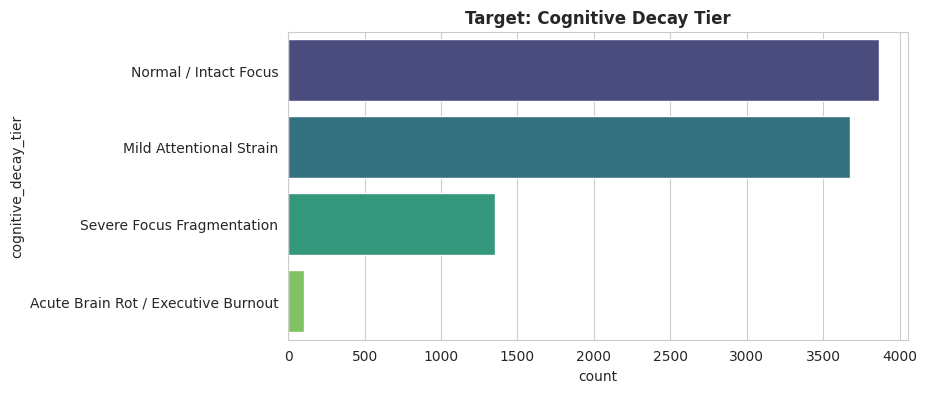

In [4]:
order = df['cognitive_decay_tier'].value_counts().index
plt.figure(figsize=(8,4))
sns.countplot(y='cognitive_decay_tier', data=df, order=order, palette='viridis')
plt.title('Target: Cognitive Decay Tier',fontweight='bold'); plt.show()

Do heavy users have shorter attention spans? Let's compare key numbers across tiers.

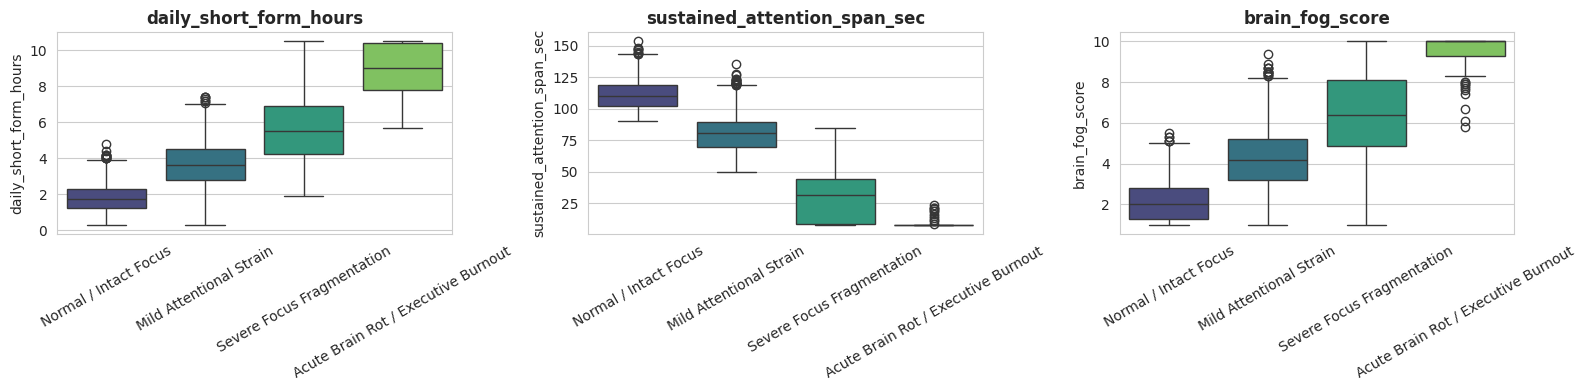

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))
for a, c in zip(ax, ['daily_short_form_hours','sustained_attention_span_sec','brain_fog_score']):
    sns.boxplot(x='cognitive_decay_tier', y=c, data=df, order=order, ax=a, palette='viridis')
    a.set_xlabel(''); a.tick_params(axis='x', rotation=30); a.set_title(c,fontweight='bold')
plt.tight_layout(); plt.show()

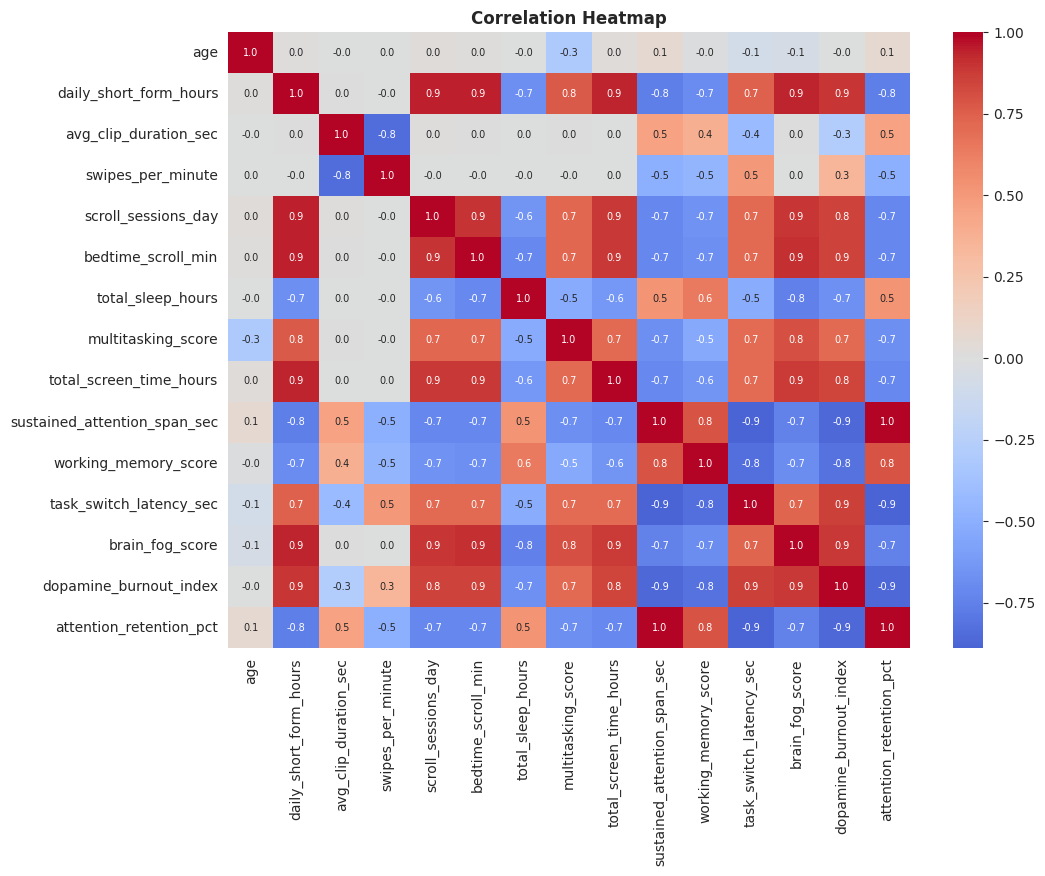

In [6]:
num = df.select_dtypes('number')
plt.figure(figsize=(11,8))
sns.heatmap(num.corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size':7})
plt.title('Correlation Heatmap',fontweight='bold'); plt.show()

**Takeaway:** more screen time, faster swiping, and less sleep go together with weaker attention and more brain fog.

## **4. Data Preparation**
- Drop `participant_id` (just a label, no meaning)
- Turn text columns (gender, platform) into numbers (one-hot encoding)
- Split **80% train / 20% test** (keeping class proportions with `stratify`)

In [7]:
y = df['cognitive_decay_tier']
X = pd.get_dummies(df.drop(columns=['participant_id','cognitive_decay_tier']), drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(X_train)          # scaling helps Logistic Regression
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(7200, 20) (1800, 20)


## **5. Train Models: Baseline → Top**
| Model | Why |
|---|---|
| Dummy | Baseline: always guesses the most common class |
| Logistic Regression | Simple linear model |
| Decision Tree | Easy to explain |
| Random Forest | Many trees voting |
| Hist Gradient Boosting | Strong boosting model |

In [8]:
models = {
    'Dummy (baseline)':    (DummyClassifier(strategy='most_frequent'), False),
    'Logistic Regression': (LogisticRegression(max_iter=3000), True),
    'Decision Tree':       (DecisionTreeClassifier(max_depth=8, random_state=SEED), False),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), False),
    'Hist Gradient Boosting': (HistGradientBoostingClassifier(random_state=SEED), False),
}
rows, preds = [], {}
for name, (m, scaled) in models.items():
    A, B = (Xtr_s, Xte_s) if scaled else (X_train, X_test)
    m.fit(A, y_train); p = m.predict(B); preds[name] = p
    rows.append([name, accuracy_score(y_test, p), f1_score(y_test, p, average='macro')])
res = pd.DataFrame(rows, columns=['Model','Accuracy','Macro F1']).sort_values('Macro F1', ascending=False).round(4)
res

,Model,Accuracy,Macro F1
2,Decision Tree,0.9994,0.9937
3,Random Forest,0.9983,0.9922
4,Hist Gradient Boosting,0.9939,0.9756
1,Logistic Regression,0.9233,0.8856
0,Dummy (baseline),0.4294,0.1502


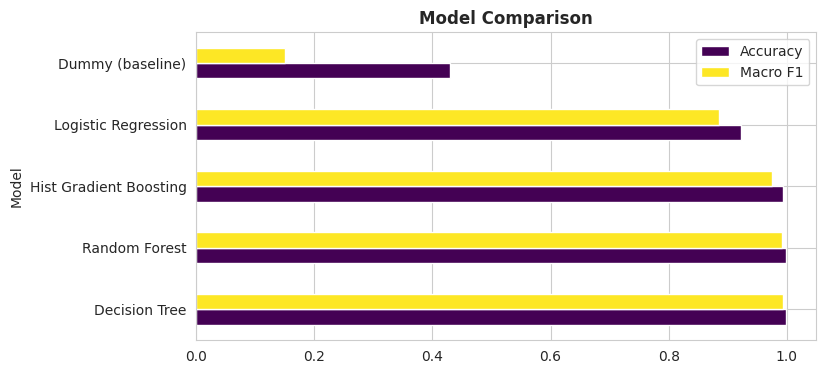

In [9]:
res.set_index('Model')[['Accuracy','Macro F1']].plot(kind='barh', figsize=(8,4), colormap='viridis')
plt.title('Model Comparison',fontweight='bold'); plt.xlim(0,1.05); plt.show()

## **6. Best Model: Cross-Validation & Detailed Report**
Cross-validation tests the model on 5 different splits, so we know the score is not just luck.

In [10]:
best = DecisionTreeClassifier(max_depth=8, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scores = cross_val_score(best, X, y, cv=cv, scoring='f1_macro')
print('5-fold Macro F1: %.4f (+/- %.4f)' % (scores.mean(), scores.std()))
best.fit(X_train, y_train); p = best.predict(X_test)
print(classification_report(y_test, p))

5-fold Macro F1: 0.9971 (+/- 0.0036)
                                     precision    recall  f1-score   support

Acute Brain Rot / Executive Burnout       0.95      1.00      0.98        21
            Mild Attentional Strain       1.00      1.00      1.00       735
              Normal / Intact Focus       1.00      1.00      1.00       773
         Severe Focus Fragmentation       1.00      1.00      1.00       271

                           accuracy                           1.00      1800
                          macro avg       0.99      1.00      0.99      1800
                       weighted avg       1.00      1.00      1.00      1800



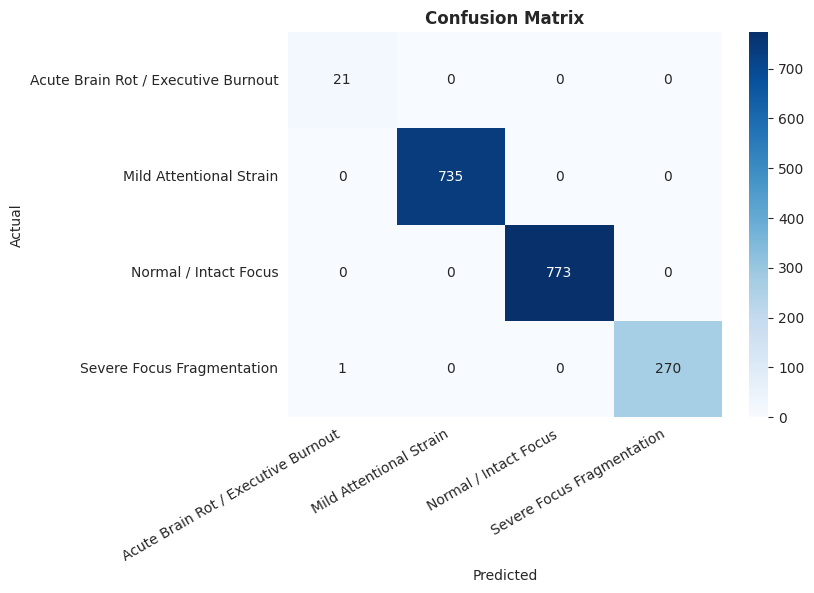

In [11]:
labels = sorted(y.unique())
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, p, labels=labels), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xticks(rotation=30, ha='right'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix',fontweight='bold'); plt.show()

## **7. What Matters Most? (Feature Importance)**

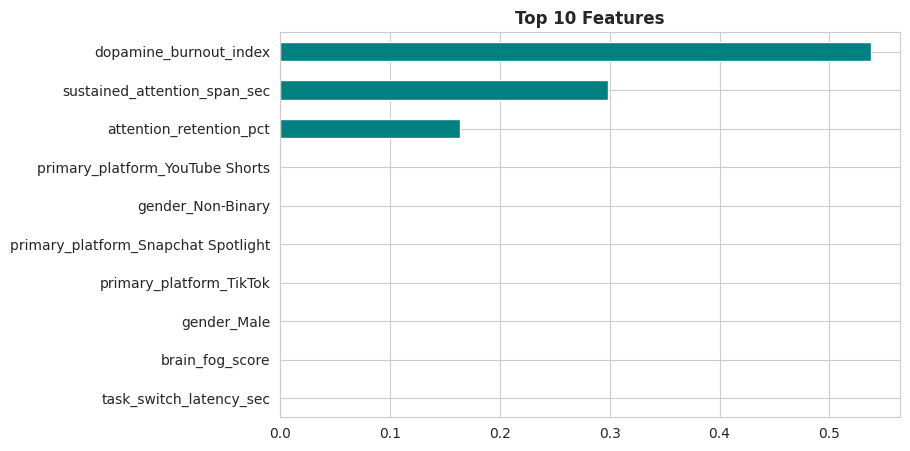

In [12]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind='barh', figsize=(8,5), color='teal'); plt.title('Top 10 Features',fontweight='bold'); plt.show()

## **8. Reality Check: Habits-Only Model**
The columns `sustained_attention_span_sec`, `working_memory_score`, `task_switch_latency_sec`, `brain_fog_score`, `dopamine_burnout_index` and `attention_retention_pct` are **measured brain-health results**, so they are very close to the tier itself and make prediction easy.

A more useful question: **can we predict the tier from daily habits alone** (hours, swipes, sleep, platform, age...)? Let's test that.

In [13]:
cog_cols = ['sustained_attention_span_sec','working_memory_score','task_switch_latency_sec',
            'brain_fog_score','dopamine_burnout_index','attention_retention_pct']
Xh = X.drop(columns=cog_cols)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, y, test_size=0.2, stratify=y, random_state=SEED)
sch = StandardScaler().fit(Xh_tr)
rows = []
for name, m, s in [('Logistic Regression', LogisticRegression(max_iter=3000), True),
                   ('Random Forest', RandomForestClassifier(300, random_state=SEED, n_jobs=-1), False),
                   ('Hist Gradient Boosting', HistGradientBoostingClassifier(random_state=SEED), False)]:
    A, B = (sch.transform(Xh_tr), sch.transform(Xh_te)) if s else (Xh_tr, Xh_te)
    q = m.fit(A, yh_tr).predict(B)
    rows.append([name, accuracy_score(yh_te, q), f1_score(yh_te, q, average='macro')])
pd.DataFrame(rows, columns=['Model (habits only)','Accuracy','Macro F1']).round(4)

,Model (habits only),Accuracy,Macro F1
0,Logistic Regression,0.8694,0.8129
1,Random Forest,0.8722,0.8078
2,Hist Gradient Boosting,0.8644,0.7870


## **9. Conclusion**
- **Data:** 9,000 people, 18 columns, no missing values. Classes are imbalanced (the *Acute Brain Rot* tier is rare), so we used **macro F1** besides accuracy.
- **Results:** the baseline guesses ~43%. Logistic Regression reaches ~92%, while the **Decision Tree** is the top model with ~**99.9% accuracy** and ~0.99 macro F1 (5-fold CV macro F1 ~0.99), closely followed by Random Forest (~99.8%). A simple tree winning suggests the tier is defined by clear thresholds on the cognitive scores.
- **Why so high?** The cognitive measures (attention span, brain fog, burnout index...) almost define the tier.
- **Habits-only model** still reaches ~**87% accuracy**, so daily habits (screen time, swipe speed, sleep, bedtime scrolling) alone are a strong signal for focus decay.
- **Limits & next steps:** the data looks synthetic/survey-based, so real-world scores may be lower; try hyperparameter tuning, class weights, or SMOTE for the rare class.

*If you liked it, please upvote 👍*